# Input data preparation

## Accepts .h5 and .imzml formats

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import os
import glob
import cv2
from natsort import natsorted, ns
from hyres_utils import hyres_generator
from hyres_evals import entropy_rank, info_montage

### Input directory

In [7]:
# this is the directory that contains your .imzml, .h5 .tif etc.
input_dir = 'C:/Users/LocalAdmin/Dropbox/File requests/PPserver/validation/A30_Centroid'

### Generate HR input/training images from HSI datasets in input directory

In [8]:
files = natsorted(
    [f for f in glob.glob(os.path.join(input_dir, '*'))
     if os.path.splitext(f)[1].lower() in ('.h5', '.imzml')],
    alg=ns.IGNORECASE)

for file in files:
    fmt = 'imzml' if file.lower().endswith('.imzml') else 'h5'
    _, _ = hyres_generator(os.path.basename(file), input_dir, file_format=fmt, bin_width =0.01)

n_h5 = sum(f.lower().endswith('.h5') for f in files)
n_imzml = len(files) - n_h5
print('training images generated from %d datasets (%d h5, %d imzML).'
      % (len(files), n_h5, n_imzml))

A30.imzML


C:\Users\LocalAdmin\anaconda3\envs\hyres\Lib\site-packages\pyimzml\ontology\ontology.py:92: UserWarning: Accession MS:1000563 found with incorrect name "Thermo RAW file". Updating name to "Thermo RAW format".
  warn(
C:\Users\LocalAdmin\anaconda3\envs\hyres\Lib\site-packages\pyimzml\ontology\ontology.py:92: UserWarning: Accession MS:1000590 found with incorrect name "contact organization". Updating name to "contact affiliation".
  warn(
C:\Users\LocalAdmin\anaconda3\envs\hyres\Lib\site-packages\pyimzml\ontology\ontology.py:92: UserWarning: Accession IMS:1000042 found with incorrect name "max count of pixel x". Updating name to "max count of pixels x".
  warn(
C:\Users\LocalAdmin\anaconda3\envs\hyres\Lib\site-packages\pyimzml\ontology\ontology.py:92: UserWarning: Accession IMS:1000043 found with incorrect name "max count of pixel y". Updating name to "max count of pixels y".
  warn(
C:\Users\LocalAdmin\anaconda3\envs\hyres\Lib\site-packages\pyimzml\ontology\ontology.py:92: UserWarning: 

training images generated from 1 datasets (0 h5, 1 imzML).


### Visualise the top 10 features in the HSI dataset that contain the most information (by Shannon's entropy)

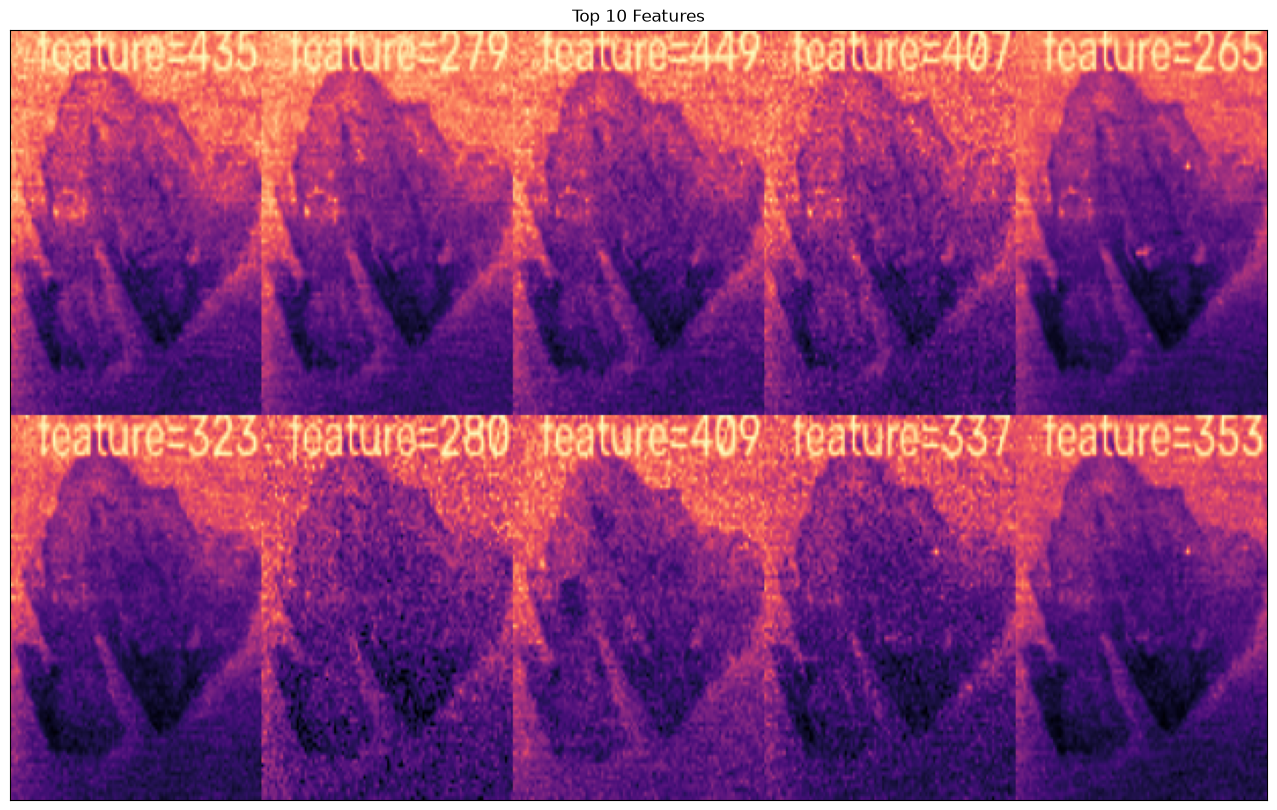

In [9]:
example_dir = os.path.splitext(files[0])[0]
ents, rank = entropy_rank(example_dir)

montages = info_montage(example_dir, rank)
for montage in montages:
    fig, ax = plt.subplots()
    ax.set_title('Top 10 Features')
    ax.set_xticks([]) 
    ax.set_yticks([])  
    ax.imshow(cv2.cvtColor(montage, cv2.COLOR_BGR2GRAY), cmap = 'magma');
    fig = plt.gcf()
    fig.set_size_inches(20, 10)

### Generate synthetic LR images to pair with HR images for training